In [118]:
#import lib

import pandas as pd
import numpy  as np

In [119]:
# Load your data

file_path = r'https://raw.githubusercontent.com/NUELBUNDI/AML_Book-Data/refs/heads/master/Data/movie_blockbusters.csv'

df = pd.read_csv(file_path)
rows , cols = df.shape

print(f'Columns {cols}\nRows:{rows}')


Columns 14
Rows:5000


In [ ]:
# (df['profit_usd'] >= df['revenue_usd']

### End to End Machine Learning Cycle

1. Problem statement
2. Collect your data
3. Prepare your data for Analysis
     
     - Data Cleaning 
          1. Duplicates
          2. Missing values
          3. Inconsistent data
          4. Value types
          5. Data distribution
4. Exploratory Data Analysis
      1. Univariate
      2. Bivariate
      3. Multi-variate

      ~ 1. Visualization
      ~ 2. Statistics / Hypothesis A/B
      ~ 3. Stats  ( Measure of central tendency)

5. End product (Report)
6. Prepare your data for  Machine Learning / Deep learning

   - Data Transformation
       1. Scaling
       2. Encoding
       3. Box-cox transformation
       4. PCA
       5. Data Leakage
       6. Class Imbalance   ~ SMOTE

   - Data Feature Engineering
      1. Create new features from existing data

   - Data Selection
       - Filter, Wrapper, Embedded methods** POA

7. Choice Model system and Algo

    1. Supervised     - Labeled Data
    2. Unsupervised   - Unlabelled Data
    3. Semi- Supervised 
    4. Reinforcement Learning

    Supervised we have 2 types problems

      
      1. Classification  ~  When we are predicted a class
           - Binary
           - Multi-class e.g
           - Multi-label  classification

      2. Regression ~ predicted a  numerical value in number line

    
    Unsupervised -- we have below

      1. Clustering   **segmentation
      2. PCA 
      3. Association rule  Apriori
      4. Market basket Analysis

8. Train
9. Evaluation your model
10. Tune your model _ Hyperparameter tuning  ~ mlflow
**Explainability**
11. Deploy
12. Monitor   ~ Data Leakage
13. Repeat the process ~~


In [121]:
# remove the scientific notation
pd.set_option('display.float_format','{:.2f}'.format)

In [122]:
#Eyeballing

df.dtypes

movie_id         int64
title           object
year             int64
decade          object
genre           object
runtime_min      int64
budget_usd     float64
revenue_usd    float64
profit_usd     float64
roi            float64
rating         float64
vote_count       int64
popularity     float64
blockbuster      int64
dtype: object

In [123]:
# check for null values

df.isnull().sum()

movie_id       0
title          0
year           0
decade         0
genre          0
runtime_min    0
budget_usd     0
revenue_usd    0
profit_usd     0
roi            0
rating         0
vote_count     0
popularity     0
blockbuster    0
dtype: int64

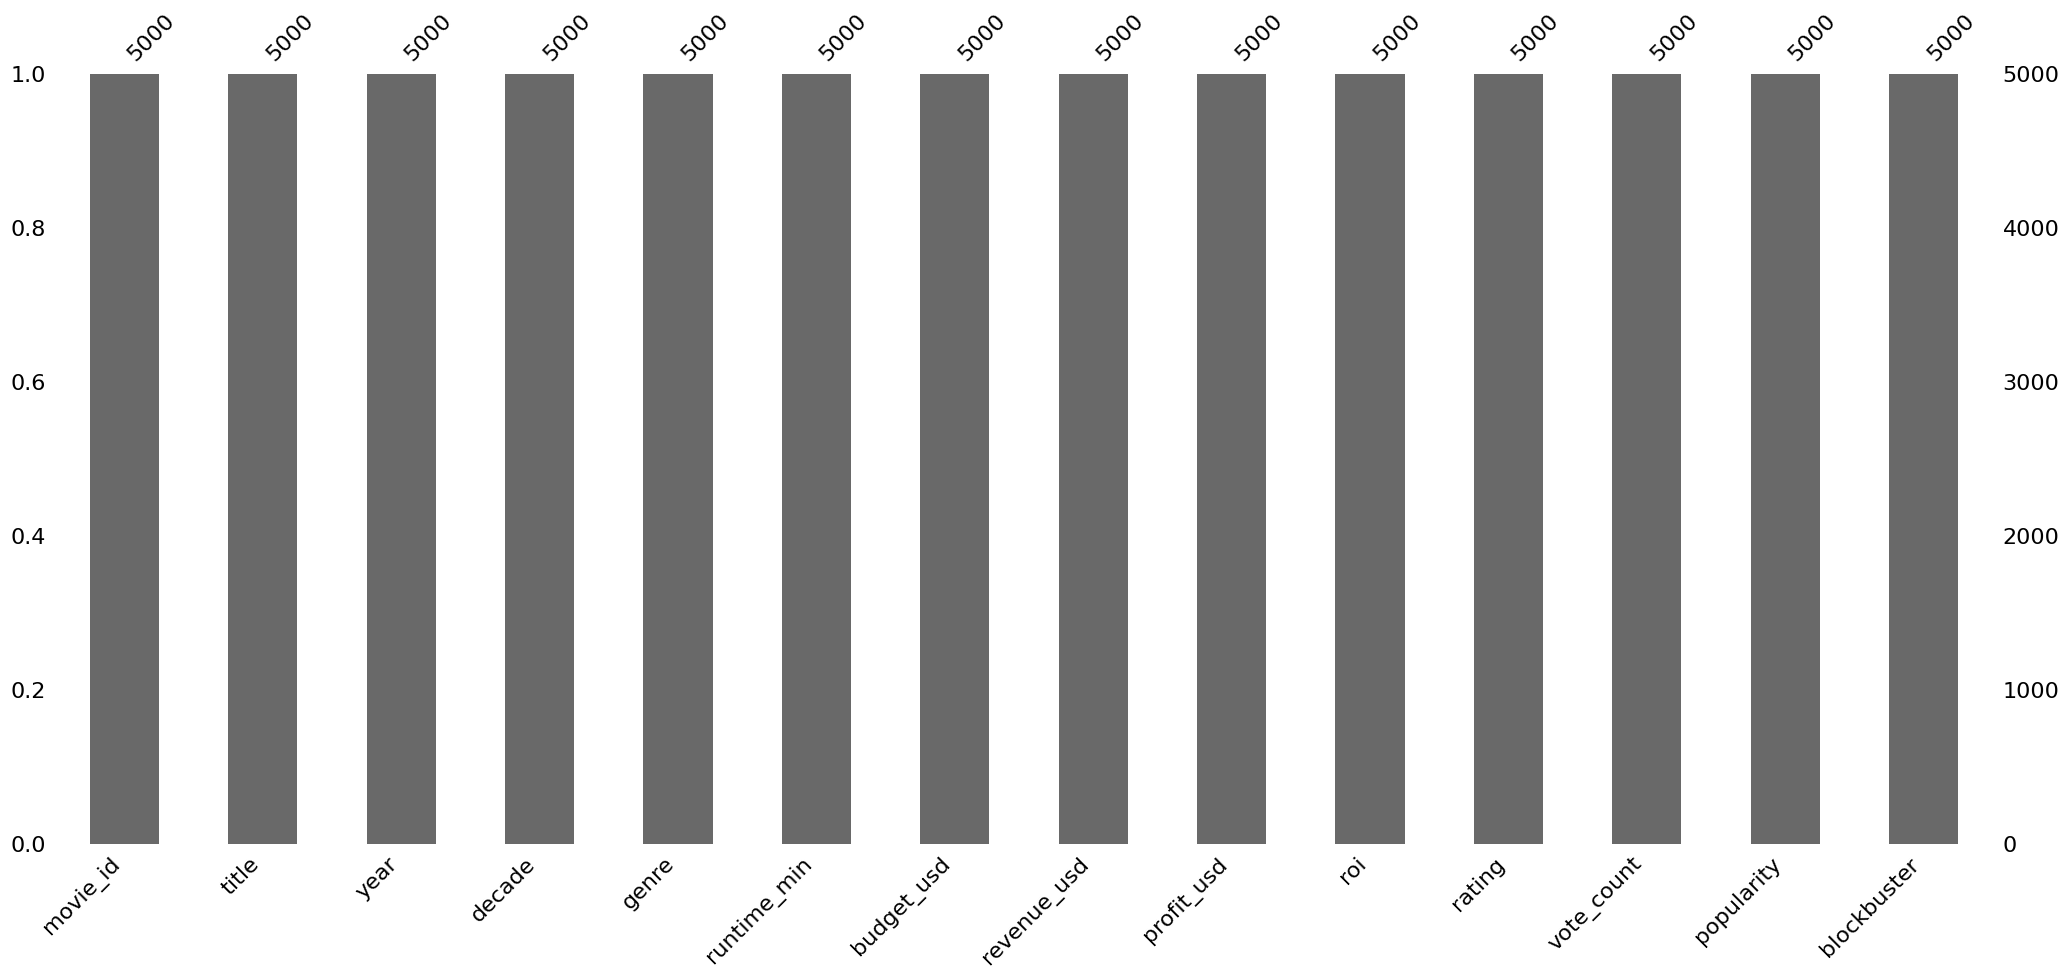

In [124]:
import missingno as mn
mn.bar(df);

In [125]:
df.isnull().sum()/len(df)* 100

movie_id      0.00
title         0.00
year          0.00
decade        0.00
genre         0.00
runtime_min   0.00
budget_usd    0.00
revenue_usd   0.00
profit_usd    0.00
roi           0.00
rating        0.00
vote_count    0.00
popularity    0.00
blockbuster   0.00
dtype: float64

In [126]:
# To Check for cardinality 

for col in df.select_dtypes(include='object').columns:
    print(f'{col} has {df[col].nunique()}')
    

title has 5000
decade has 5
genre has 10


EDA

In [127]:
# Univariate Example  

# Find out the data distribution budget_usd

#pip install plotly.express

# Visualization page in python
import plotly_express as px       #  Well styled chart in render in the web
import matplotlib.pyplot as plt   #  Low-level , highly customizable
import seaborn as sns             #  Focus is stast

In [128]:
# histogram
fig =  px.histogram(
    data_frame= df,
    x='revenue_usd'
)

fig.update_layout(
    title ='Revenue in USD Distribution',
    yaxis_title='Frequency',
    xaxis_title='Revenue USD'
)

fig.show()

In [129]:
px.box(
    data_frame=df,
    y='revenue_usd'
    
)

In [130]:
df['revenue_usd'].describe()

count          5000.00
mean      131184400.53
std       501258050.25
min           14032.44
25%         5707046.69
50%        23279983.03
75%        88871335.98
max     14955184373.97
Name: revenue_usd, dtype: float64

# what can we do??
- Use Robust scaler 
- We can treat outliers
- 

How do we treat outliers (Lets use IQR)

In [131]:
def treat_outliers(df:pd.DataFrame,col:str):
    
    q1= df[col].quantile(.25)
    q3= df[col].quantile(.75)
    
    iqr = q3-q1
    
    # we can now cal the upper and lower bound
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    df[col] = df[col].clip(lower=lower_bound,upper= upper_bound)
    
    return df
    
    
    
    

In [132]:

    
for col in ['budget_usd','revenue_usd','profit_usd']: 
    treat_outliers(df,col)



In [133]:
# Lets use our 

treat_outliers(df,'revenue_usd')

fig =  px.histogram(
    data_frame= df,
    x='revenue_usd'
)

fig.update_layout(
    title ='Revenue in USD Distribution',
    yaxis_title='Frequency',
    xaxis_title='Revenue USD'
)

fig.show()


In [134]:
fig =  px.histogram(
    data_frame= df,
    x='rating'
)

fig.update_layout(
    title ='Revenue in Rating',
    yaxis_title='Frequency',
    xaxis_title='Rating'
)

fig.show()


In [135]:
# Bivariate Analysis

df.groupby('genre')['runtime_min'].mean().sort_values().reset_index()

,genre,runtime_min
0,Documentary,84.80
1,Animation,93.77
2,Horror,94.17
3,Comedy,99.44
4,Romance,104.46
5,Thriller,109.89
6,Drama,119.49
7,Adventure,125.70
8,Action,129.38
9,Sci-Fi,135.32


In [136]:
# which movie has lowest title

min_budget= df['budget_usd'].min()

df[df['budget_usd']==min_budget]

,movie_id,title,year,decade,genre,runtime_min,budget_usd,revenue_usd,profit_usd,roi,rating,vote_count,popularity,blockbuster
2934,2935,Movie_2935,2015,2010s,Documentary,61,105489.73,36891.46,-68598.27,-0.65,6.10,31661,15.25,0


In [137]:
max_budget= df['budget_usd'].max()

df[df['budget_usd']==max_budget]

,movie_id,title,year,decade,genre,runtime_min,budget_usd,revenue_usd,profit_usd,roi,rating,vote_count,popularity,blockbuster
1,2,Movie_0002,1981,1980s,Sci-Fi,128,97186071.85,213617769.91,112046272.02,3.04,5.30,49703,7.65,1
9,10,Movie_0010,2012,2010s,Adventure,129,97186071.85,213617769.91,112046272.02,4.31,4.70,13851,32.32,1
26,27,Movie_0027,1998,1990s,Adventure,110,97186071.85,213617769.91,112046272.02,2.52,4.20,58972,26.76,1
27,28,Movie_0028,2003,2000s,Adventure,137,97186071.85,159299522.55,14003665.78,0.10,7.40,40911,81.19,0
51,52,Movie_0052,1989,1980s,Sci-Fi,131,97186071.85,213617769.91,40302779.43,0.19,6.80,16264,36.55,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4949,4950,Movie_4950,2000,2000s,Adventure,135,97186071.85,213617769.91,112046272.02,2.69,8.60,72439,7.26,1
4956,4957,Movie_4957,2020,2020s,Sci-Fi,136,97186071.85,213617769.91,112046272.02,5.42,5.30,34328,23.56,1
4977,4978,Movie_4978,2007,2000s,Thriller,83,97186071.85,213617769.91,112046272.02,2.36,6.10,11321,5.10,1
4988,4989,Movie_4989,2008,2000s,Animation,92,97186071.85,213617769.91,78583150.60,0.44,6.10,11473,4.59,0


In [138]:
df['decade'].value_counts()

decade
2000s    1148
1980s    1106
1990s    1081
2010s    1079
2020s     586
Name: count, dtype: int64

In [139]:
pd.set_option('display.float_format','{:,.2f}'.format)

In [140]:
df.groupby('genre').agg(
    {
        'budget_usd':'mean',
        'revenue_usd':'mean',
        'profit_usd' :'mean',
        'roi':'mean',
        'rating':'mean',
        'popularity':'mean',
        'decade':'count',
        
    }
).reset_index()

,genre,budget_usd,revenue_usd,profit_usd,roi,rating,popularity,decade
0,Action,"49,634,998.63","109,570,981.72","48,465,599.41",2.33,6.01,20.05,488
1,Adventure,"47,328,049.94","103,420,309.10","45,381,544.31",2.34,5.95,20.86,515
2,Animation,"42,982,204.40","106,186,911.74","52,843,721.03",2.97,5.96,19.53,522
3,Comedy,"20,542,619.04","38,274,495.19","15,107,717.43",1.13,6.01,18.95,499
4,Documentary,"5,099,910.33","3,279,969.50","-1,819,940.83",-0.36,6.05,19.93,544
5,Drama,"18,467,832.22","27,826,916.11","7,769,495.57",0.59,6.02,19.20,507
6,Horror,"11,990,330.19","40,571,589.08","25,525,889.73",3.25,5.91,21.82,477
7,Romance,"16,888,353.59","22,814,587.19","4,499,002.23",0.34,6.03,20.72,471
8,Sci-Fi,"52,350,615.64","109,176,308.50","43,794,343.72",1.92,6.00,17.66,478
9,Thriller,"24,907,765.83","41,208,380.73","13,365,171.42",0.81,6.03,21.35,499


In [141]:
# Multivariate Analysis

df

,movie_id,title,year,decade,genre,runtime_min,budget_usd,revenue_usd,profit_usd,roi,rating,vote_count,popularity,blockbuster
0,1,Movie_0001,2020,2020s,Comedy,96,"20,892,328.61","27,392,091.72","6,499,763.11",0.31,7.00,216326,9.64,0
1,2,Movie_0002,1981,1980s,Sci-Fi,128,"97,186,071.85","213,617,769.91","112,046,272.02",3.04,5.30,49703,7.65,1
2,3,Movie_0003,1995,1990s,Horror,79,"8,793,950.08","4,667,245.80","-4,126,704.27",-0.47,3.40,9476,16.68,0
3,4,Movie_0004,1988,1980s,Comedy,101,"3,871,709.60","1,612,737.45","-2,258,972.15",-0.58,8.20,15698,2.93,0
4,5,Movie_0005,2023,2020s,Documentary,75,"1,283,538.54","574,346.89","-709,191.65",-0.55,4.30,38698,9.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,4996,Movie_4996,2021,2020s,Comedy,71,"25,484,024.19","55,600,857.32","30,116,833.14",1.18,7.40,181516,1.17,0
4996,4997,Movie_4997,2002,2000s,Comedy,75,"90,455,850.14","40,174,409.15","-50,281,440.99",-0.56,4.40,14308,8.32,0
4997,4998,Movie_4998,1998,1990s,Documentary,79,"790,692.29","259,544.79","-531,147.50",-0.67,6.40,13156,15.77,0
4998,4999,Movie_4999,2012,2010s,Documentary,98,"8,636,782.98","14,801,451.95","6,164,668.97",0.71,5.70,340215,3.55,0
